# Punto 2 — Analisis TCRM y Forecast
**Prueba Practica Analista de Datos — Pragma**  
Tasa de Cambio Representativa del Mercado (COP/USD)  
Rango: 1991-12-02 → 2021-10-19 | Forecast: → 2023-01-01

---
## PASO 1 — Setup del entorno
Importacion de librerias, configuracion del path y estilo visual.

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from statsmodels.tsa.seasonal import STL
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tcrm_forecast import (
    load_tcrm_raw, clean_tcrm, build_daily_series,
    get_tcrm_at_date, get_integrity_report,
)

plt.rcParams.update({"figure.figsize": (14, 6), "figure.dpi": 100})
sns.set_style("whitegrid")
print("[OK] Entorno listo.")

[OK] Entorno listo.


---
## PASO 2 — Carga y preparacion de datos
Se ejecuta el pipeline ETL del modulo `tcrm_forecast`:
1. Carga del Excel historico (7,188 registros originales)
2. Limpieza de la columna `VALOR` (coma de miles → float)
3. Expansion de filas multi-dia y forward-fill para dias no transados
4. Serie diaria resultante: **10,915 dias** calendario continuos

Si el archivo Parquet ya existe se carga directamente para ahorrar tiempo.

In [2]:
PARQUET_PATH = PROJECT_ROOT / "data" / "processed" / "tcrm_diaria_procesada.parquet"

if PARQUET_PATH.exists():
    tcrm_series = pd.read_parquet(PARQUET_PATH)["tcrm"]
    print(f"[OK] Serie cargada desde Parquet: {len(tcrm_series):,} registros")
    df_raw = load_tcrm_raw()
    df_clean = clean_tcrm(df_raw)
    n_original = len(df_clean)
else:
    from tcrm_forecast import run_tcrm_pipeline
    tcrm_series = run_tcrm_pipeline()
    df_raw = load_tcrm_raw()
    df_clean = clean_tcrm(df_raw)
    n_original = len(df_clean)

tcrm_series.head(10)

[OK] Serie cargada desde Parquet: 10,915 registros
[TCRM] Cargando datos crudos desde Excel...


  [OK] Cargadas 7,188 filas | 4 columnas
[TCRM] Limpiando y normalizando datos...
  [OK] Rango de datos: 1991-12-02 -> 2021-10-19
  [OK] 7,188 registros limpios | Valor TCRM: 620.62 - 4,153.91 COP


fecha
1991-12-02    643.42
1991-12-03    639.22
1991-12-04    635.70
1991-12-05    631.51
1991-12-06    627.16
1991-12-07    638.06
1991-12-08    638.06
1991-12-09    638.06
1991-12-10    622.92
1991-12-11    627.46
Name: tcrm, dtype: float64

---
## PASO 3 — Punto 2.a: Consulta puntual TCRM
Extraccion del valor TCRM para la fecha de expedicion de cedula: **2010-04-19**  
Valor de referencia esperado: **$1,942.21 COP**

In [3]:
CEDULA_DATE = "2010-04-19"
EXPECTED = 1942.21

tcrm_cedula = get_tcrm_at_date(tcrm_series, CEDULA_DATE)
match = abs(tcrm_cedula - EXPECTED) < 0.01

print("=" * 55)
print(f"  CONSULTA PUNTUAL TCRM")
print("=" * 55)
print(f"  Fecha expedicion cedula : {CEDULA_DATE}")
print(f"  TCRM observada          : ${tcrm_cedula:,.2f} COP")
print(f"  Valor referencia        : ${EXPECTED:,.2f} COP")
print(f"  Coincidencia            : {'SI' if match else 'NO'}")
print("=" * 55)

  CONSULTA PUNTUAL TCRM
  Fecha expedicion cedula : 2010-04-19
  TCRM observada          : $1,942.21 COP
  Valor referencia        : $1,942.21 COP
  Coincidencia            : SI


---
## PASO 4 — Punto 2.b: Reporte de integridad
Validacion de completitud de la serie: total de dias, registros originales y dias imputados via forward-fill segun normativa SFC.

In [4]:
report = get_integrity_report(tcrm_series, n_original)
pct_orig = report["registros_originales"] / report["total_dias_calendario"] * 100
pct_imp = report["dias_no_transados"] / report["total_dias_calendario"] * 100

print("=" * 55)
print(f"  REPORTE DE INTEGRIDAD")
print("=" * 55)
print(f"  Fecha inicio                : {report['fecha_inicio']}")
print(f"  Fecha fin                   : {report['fecha_fin']}")
print(f"  Total dias calendario       : {report['total_dias_calendario']:,}")
print(f"  Registros dataset original  : {report['registros_originales']:,}  ({pct_orig:.1f}%)")
print(f"  Dias no transados (ffill)   : {report['dias_no_transados']:,}  ({pct_imp:.1f}%)")
print(f"  Metodo imputacion           : Forward Fill (Circular DODM-146 SFC)")
print(f"  Valores nulos en serie final: {tcrm_series.isna().sum()}")
print("=" * 55)

  REPORTE DE INTEGRIDAD
  Fecha inicio                : 1991-12-02
  Fecha fin                   : 2021-10-19
  Total dias calendario       : 10,915
  Registros dataset original  : 7,188  (65.9%)
  Dias no transados (ffill)   : 3,727  (34.1%)
  Metodo imputacion           : Forward Fill (Circular DODM-146 SFC)
  Valores nulos en serie final: 0


---
## PASO 5 — Punto 2.c: Analisis exploratorio

### 5.1 — Serie historica completa TCRM vs Tiempo

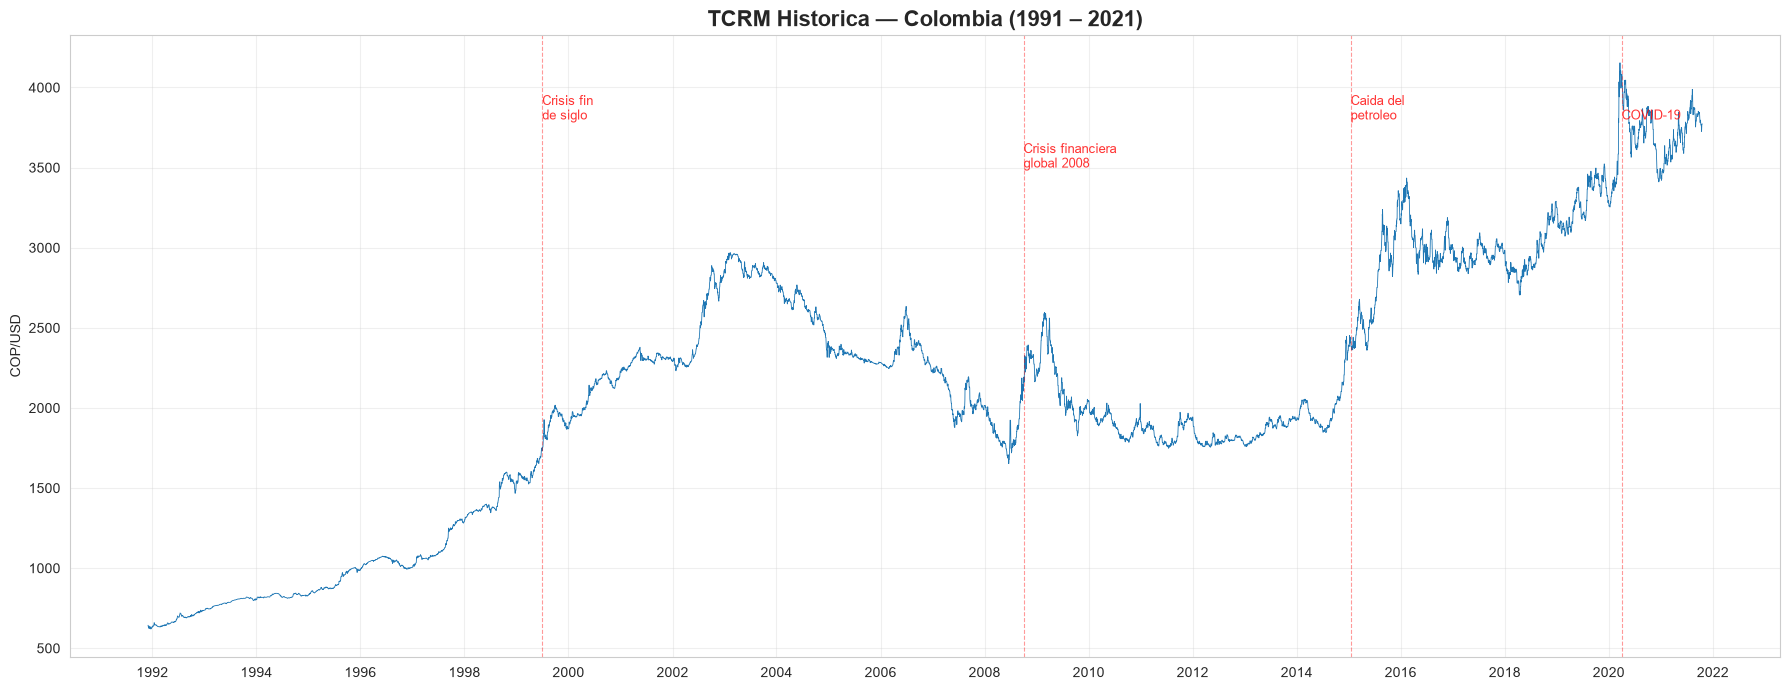

In [5]:
fig, ax = plt.subplots(figsize=(18, 7))
ax.plot(tcrm_series.index, tcrm_series.values, linewidth=0.6, color="#1f77b4")
ax.set_title("TCRM Historica — Colombia (1991 – 2021)", fontsize=16, fontweight="bold")
ax.set_ylabel("COP/USD")
ax.xaxis.set_major_locator(mdates.YearLocator(2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.grid(True, alpha=0.3)

hitos = {
    "1999-07-01": (3800, "Crisis fin\nde siglo"),
    "2008-10-01": (3500, "Crisis financiera\nglobal 2008"),
    "2015-01-15": (3800, "Caida del\npetroleo"),
    "2020-04-01": (3800, "COVID-19"),
}
for date_str, (y, label) in hitos.items():
    ax.axvline(pd.Timestamp(date_str), color="red", linestyle="--", alpha=0.4, linewidth=0.8)
    ax.text(pd.Timestamp(date_str), y, label, fontsize=9, color="red", alpha=0.8)

plt.tight_layout()
plt.show()

### 5.2 — Descomposicion STL (Tendencia, Estacionalidad, Residuo)
Periodo estacional = 365 dias. STL con LOESS robusto.

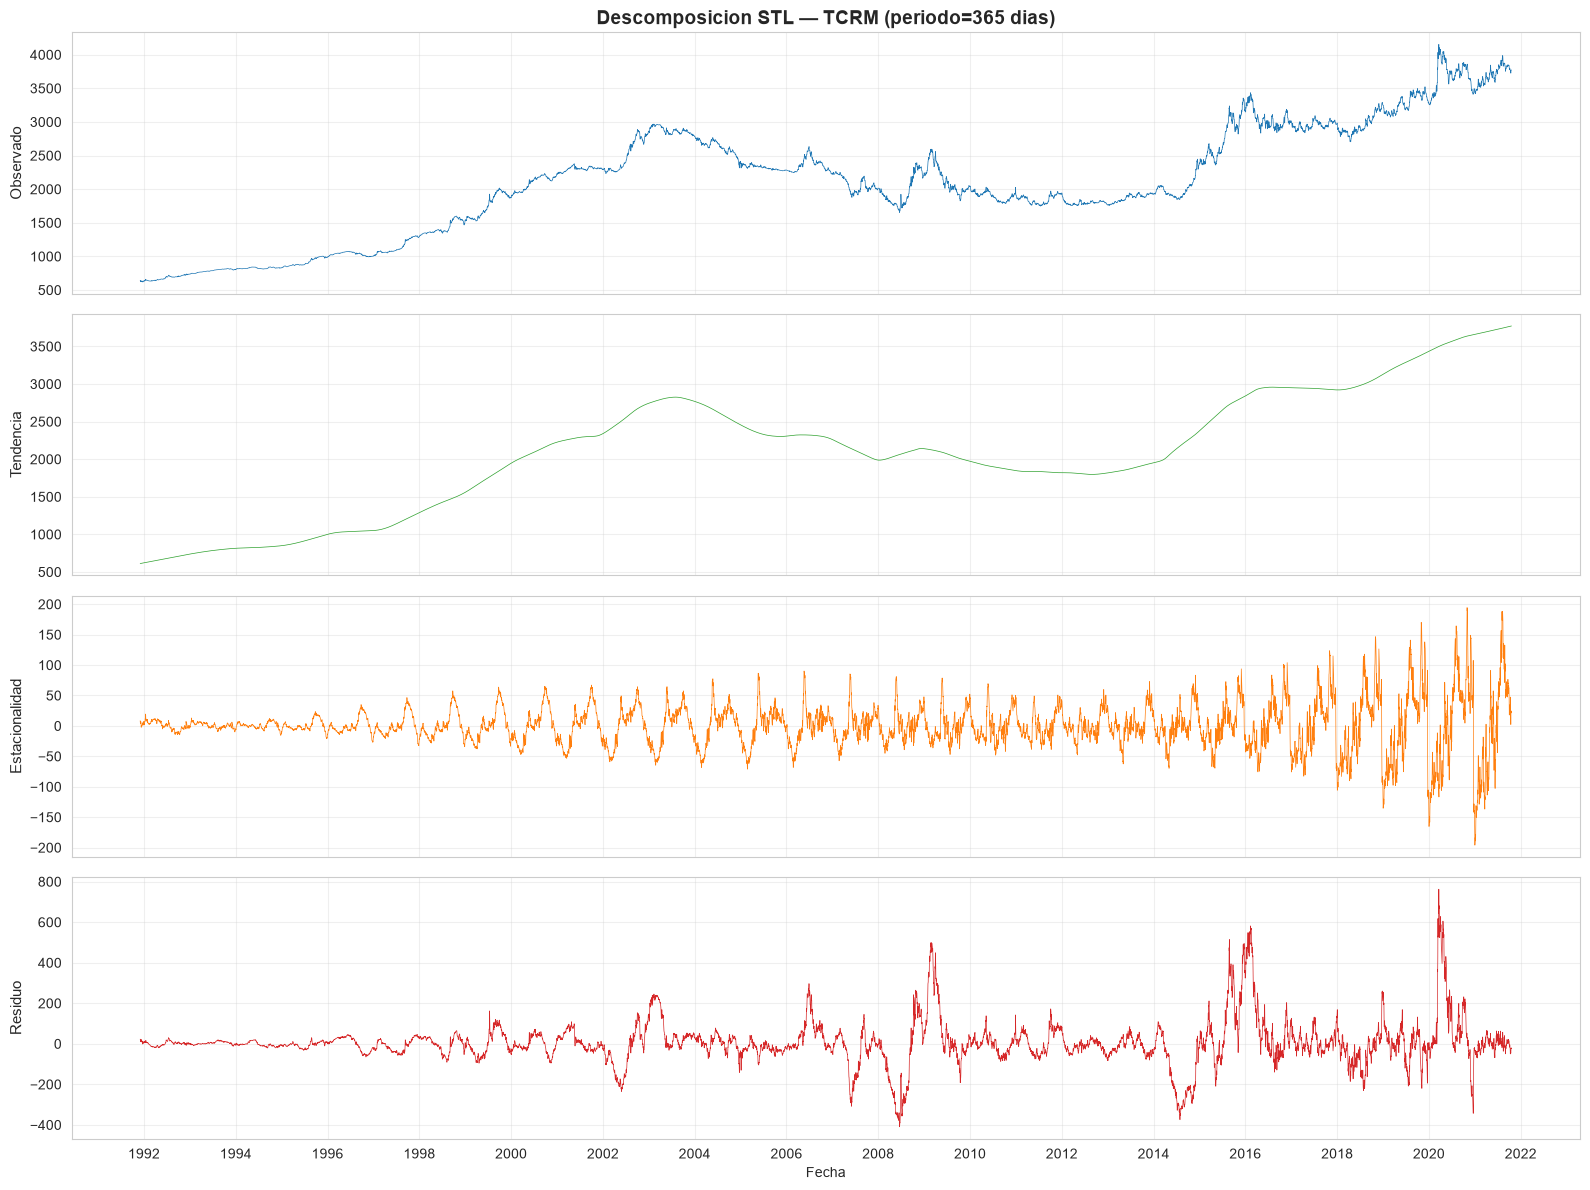

Desviacion estandar residuo: 109.02 COP
Rango residuo: [-409.35, 762.62]


In [6]:
stl = STL(tcrm_series.dropna(), period=365, seasonal=13, robust=True)
res_stl = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)
titles = ["Observado", "Tendencia", "Estacionalidad", "Residuo"]
colors = ["#1f77b4", "#2ca02c", "#ff7f0e", "#d62728"]
series_list = [res_stl.observed, res_stl.trend, res_stl.seasonal, res_stl.resid]

for ax, title, color, s in zip(axes, titles, colors, series_list):
    ax.plot(s.index, s.values, linewidth=0.5, color=color)
    ax.set_ylabel(title, fontsize=11)
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.grid(True, alpha=0.3)

axes[0].set_title("Descomposicion STL — TCRM (periodo=365 dias)", fontsize=14, fontweight="bold")
axes[3].set_xlabel("Fecha")
plt.tight_layout()
plt.show()

print(f"Desviacion estandar residuo: {res_stl.resid.std():,.2f} COP")
print(f"Rango residuo: [{res_stl.resid.min():,.2f}, {res_stl.resid.max():,.2f}]")

### 5.3 — Volatilidad: medias moviles y desviacion estandar movil

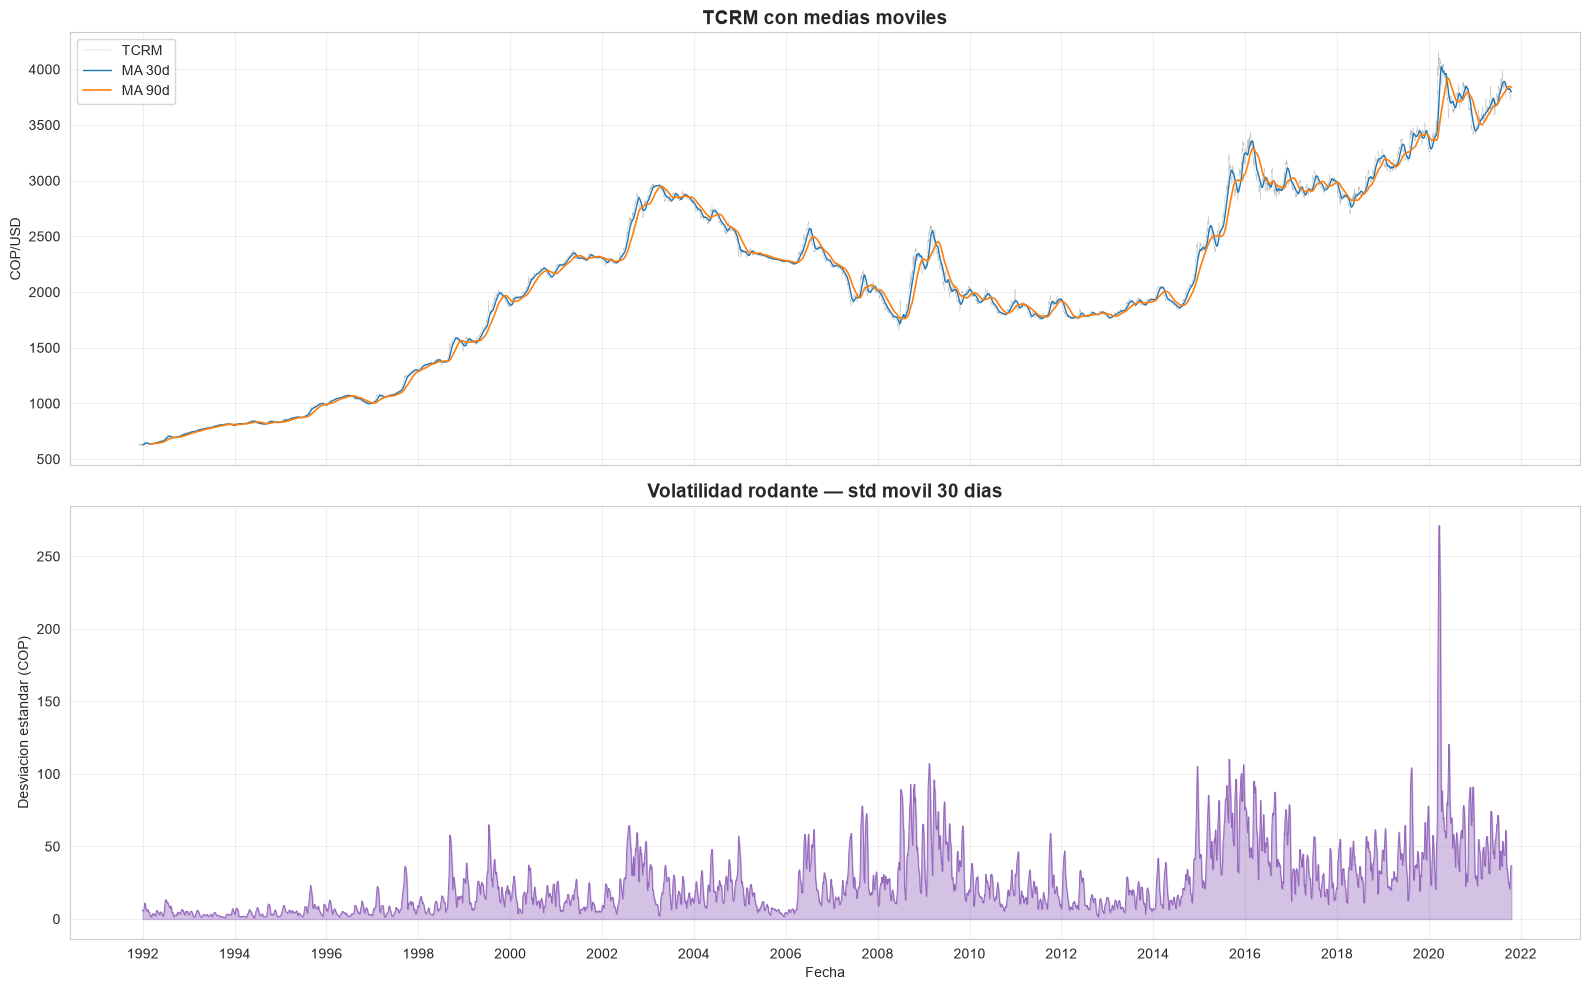

Volatilidad promedio (std 30d): 24.90 COP
Volatilidad maxima  (std 30d): 271.31 COP  (2020-03-23)


In [7]:
ma30 = tcrm_series.rolling(30).mean()
ma90 = tcrm_series.rolling(90).mean()
std30 = tcrm_series.rolling(30).std()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=True)

ax1.plot(tcrm_series.index, tcrm_series.values, linewidth=0.3, color="gray", alpha=0.5, label="TCRM")
ax1.plot(ma30.index, ma30.values, linewidth=1.0, label="MA 30d")
ax1.plot(ma90.index, ma90.values, linewidth=1.2, label="MA 90d")
ax1.set_ylabel("COP/USD")
ax1.set_title("TCRM con medias moviles", fontsize=14, fontweight="bold")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)

ax2.fill_between(std30.index, 0, std30.values, alpha=0.4, color="#9467bd")
ax2.plot(std30.index, std30.values, linewidth=0.7, color="#9467bd")
ax2.set_ylabel("Desviacion estandar (COP)")
ax2.set_xlabel("Fecha")
ax2.set_title("Volatilidad rodante — std movil 30 dias", fontsize=14, fontweight="bold")
ax2.grid(True, alpha=0.3)

for ax in (ax1, ax2):
    ax.xaxis.set_major_locator(mdates.YearLocator(2))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

plt.tight_layout()
plt.show()

print(f"Volatilidad promedio (std 30d): {std30.mean():,.2f} COP")
print(f"Volatilidad maxima  (std 30d): {std30.max():,.2f} COP  ({std30.idxmax().strftime('%Y-%m-%d')})")

### 5.4 — Conclusiones del analisis exploratorio

**Seis regimenes cambiarios identificados:**

| # | Periodo | Regimen | TCRM (aprox) |
|---|---------|---------|-------------|
| 1 | 1991–1998 | Banda cambiaria (crawling peg) | $643 → $1,500 |
| 2 | 1998–2003 | Crisis fin de siglo + flotacion (1999) | $1,500 → $2,900 |
| 3 | 2003–2013 | Apreciacion sostenida (super-peso) | $2,900 → $1,750 |
| 4 | 2014–2016 | Devaluacion post-caida del petroleo | $1,900 → $3,400 |
| 5 | 2017–2019 | Estabilizacion en rango alto | $2,800 – $3,400 |
| 6 | 2020–2021 | Shock COVID-19 y recuperacion | $3,200 – $4,154 |

**Hallazgos clave:**
- **Tendencia:** No estacionaria, con cambios estructurales asociados a eventos macroeconomicos.
- **Estacionalidad:** Debil (~ ±50 COP), tipica de series financieras.
- **Volatilidad:** Heterocedastica, con clusters pronunciados en periodos de crisis (1999, 2008, 2014, 2020).
- **Maximo historico:** $4,153.91 COP (abril 2020, COVID-19).

---
## PASO 6 — Punto 2.d: Modelado de forecast (h = 439 dias)

### 6.1 — Definicion del horizonte y split Train / Validation

In [8]:
FORECAST_START = pd.Timestamp("2021-10-20")
FORECAST_END   = pd.Timestamp("2023-01-01")
HORIZON = (FORECAST_END - FORECAST_START).days + 1

split_idx = int(len(tcrm_series) * 0.8)
train = tcrm_series.iloc[:split_idx].copy()
val   = tcrm_series.iloc[split_idx:].copy()

print(f"Horizonte forecast : h = {HORIZON} dias")
print(f"Inicio forecast    : {FORECAST_START.strftime('%Y-%m-%d')}")
print(f"Fin forecast       : {FORECAST_END.strftime('%Y-%m-%d')}")
print(f"Train: {len(train):,} dias | {train.index.min().strftime('%Y-%m-%d')} -> {train.index.max().strftime('%Y-%m-%d')}")
print(f"Val:   {len(val):,} dias | {val.index.min().strftime('%Y-%m-%d')} -> {val.index.max().strftime('%Y-%m-%d')}")

Horizonte forecast : h = 439 dias
Inicio forecast    : 2021-10-20
Fin forecast       : 2023-01-01
Train: 8,732 dias | 1991-12-02 -> 2015-10-28
Val:   2,183 dias | 2015-10-29 -> 2021-10-19


### 6.2 — Modelo AutoARIMA / SARIMA
Busqueda automatica de parametros (p,d,q)(P,D,Q,m) con criterio AIC.

In [9]:
from pmdarima import auto_arima

print("[SARIMA] Buscando parametros optimos (puede tomar ~2-3 min)...")

auto_model = auto_arima(
    train, seasonal=True, m=7,
    start_p=1, start_q=1, max_p=3, max_q=3,
    start_P=0, start_Q=0, max_P=2, max_Q=2,
    d=None, D=None, stepwise=True,
    error_action="ignore", suppress_warnings=True,
    n_jobs=-1, information_criterion="aic",
)
print(f"[SARIMA] Mejor modelo: {auto_model.order} x {auto_model.seasonal_order}  |  AIC={auto_model.aic():,.2f}")

# Prediccion en validacion
sarima_pred_val, _ = auto_model.predict(n_periods=len(val), return_conf_int=True, alpha=0.05)
sarima_pred_val = pd.Series(sarima_pred_val, index=val.index)
sarima_mae  = mean_absolute_error(val, sarima_pred_val)
sarima_rmse = np.sqrt(mean_squared_error(val, sarima_pred_val))
print(f"[SARIMA] Validacion -> MAE={sarima_mae:,.2f} COP | RMSE={sarima_rmse:,.2f} COP")

# Reentrenar con datos completos
print("[SARIMA] Reentrenando con serie completa...")
final_sarima = auto_arima(
    tcrm_series, seasonal=True, m=7,
    start_p=1, start_q=1, max_p=3, max_q=3,
    start_P=0, start_Q=0, max_P=2, max_Q=2,
    d=None, D=None, stepwise=True,
    error_action="ignore", suppress_warnings=True,
    n_jobs=-1, information_criterion="aic",
)
print(f"[SARIMA] Modelo final: {final_sarima.order} x {final_sarima.seasonal_order}")

# Forecast
sarima_fc, sarima_ci = final_sarima.predict(n_periods=HORIZON, return_conf_int=True, alpha=0.05)
fc_dates = pd.date_range(start=FORECAST_START, end=FORECAST_END, freq="D")
sarima_fc_series = pd.Series(sarima_fc, index=fc_dates)

# Sigma acumulada: sigma_h = sigma_residual * sqrt(h)
sarima_res = train - auto_model.predict_in_sample()
sarima_sigma_1 = np.std(sarima_res)
sarima_sigma_h = sarima_sigma_1 * np.sqrt(HORIZON)
print(f"[SARIMA] sigma_1step={sarima_sigma_1:,.2f} COP | sigma_h(h={HORIZON})={sarima_sigma_h:,.2f} COP")

[SARIMA] Buscando parametros optimos (puede tomar ~2-3 min)...


[SARIMA] Mejor modelo: (1, 1, 1) x (2, 0, 2, 7)  |  AIC=64,922.31
[SARIMA] Validacion -> MAE=193.63 COP | RMSE=231.68 COP
[SARIMA] Reentrenando con serie completa...


[SARIMA] Modelo final: (2, 1, 3) x (0, 0, 0, 7)
[SARIMA] sigma_1step=12.10 COP | sigma_h(h=439)=253.55 COP


In [10]:
sarima_pred_2023 = sarima_fc_series.loc[FORECAST_END]
sarima_lo, sarima_hi = sarima_ci[-1, 0], sarima_ci[-1, 1]

print("=" * 55)
print(f"  PREDICCION SARIMA — 2023-01-01")
print("=" * 55)
print(f"  Puntual       : ${sarima_pred_2023:,.2f} COP")
print(f"  IC 95% inf    : ${sarima_lo:,.2f} COP")
print(f"  IC 95% sup    : ${sarima_hi:,.2f} COP")
print(f"  sigma_h (439) : ${sarima_sigma_h:,.2f} COP")
print("=" * 55)

  PREDICCION SARIMA — 2023-01-01
  Puntual       : $3,898.93 COP
  IC 95% inf    : $3,264.61 COP
  IC 95% sup    : $4,533.25 COP
  sigma_h (439) : $253.55 COP


### 6.3 — Modelo Prophet
Modelo aditivo de Facebook/Meta con estacionalidad anual.

In [11]:
from prophet import Prophet

# Preparar datos
train_df = train.reset_index(); train_df.columns = ["ds", "y"]
val_df   = val.reset_index();   val_df.columns   = ["ds", "y"]
full_df  = tcrm_series.reset_index(); full_df.columns = ["ds", "y"]

print("[Prophet] Entrenando modelo...")
prophet_model = Prophet(
    changepoint_prior_scale=0.05,
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95,
)
prophet_model.fit(train_df)

# Validacion
prophet_val_fc = prophet_model.predict(pd.DataFrame({"ds": val_df["ds"]}))
prophet_mae  = mean_absolute_error(val_df["y"], prophet_val_fc["yhat"])
prophet_rmse = np.sqrt(mean_squared_error(val_df["y"], prophet_val_fc["yhat"]))
print(f"[Prophet] Validacion -> MAE={prophet_mae:,.2f} COP | RMSE={prophet_rmse:,.2f} COP")

# Reentrenar
print("[Prophet] Reentrenando con serie completa...")
prophet_final = Prophet(
    changepoint_prior_scale=0.05,
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95,
)
prophet_final.fit(full_df)

# Forecast
future = prophet_final.make_future_dataframe(periods=HORIZON, freq="D")
prophet_fc = prophet_final.predict(future)
prophet_fc_future = prophet_fc[prophet_fc["ds"] >= FORECAST_START].copy()

# Sigma acumulada
prophet_train_fc = prophet_final.predict(full_df[["ds"]])
prophet_res = full_df["y"].values - prophet_train_fc["yhat"].values
prophet_sigma_1 = np.std(prophet_res)
prophet_sigma_h = prophet_sigma_1 * np.sqrt(HORIZON)
print(f"[Prophet] sigma_1step={prophet_sigma_1:,.2f} COP | sigma_h(h={HORIZON})={prophet_sigma_h:,.2f} COP")

Importing plotly failed. Interactive plots will not work.


[Prophet] Entrenando modelo...


12:05:16 - cmdstanpy - INFO - Chain [1] start processing


12:05:19 - cmdstanpy - INFO - Chain [1] done processing


[Prophet] Validacion -> MAE=358.72 COP | RMSE=414.90 COP
[Prophet] Reentrenando con serie completa...


12:05:20 - cmdstanpy - INFO - Chain [1] start processing


12:05:22 - cmdstanpy - INFO - Chain [1] done processing


[Prophet] sigma_1step=118.82 COP | sigma_h(h=439)=2,489.65 COP


In [12]:
prophet_row = prophet_fc_future[prophet_fc_future["ds"] == FORECAST_END]
prophet_pred_2023 = prophet_row["yhat"].values[0]
prophet_lo = prophet_row["yhat_lower"].values[0]
prophet_hi = prophet_row["yhat_upper"].values[0]

print("=" * 55)
print(f"  PREDICCION PROPHET — 2023-01-01")
print("=" * 55)
print(f"  Puntual       : ${prophet_pred_2023:,.2f} COP")
print(f"  IC 95% inf    : ${prophet_lo:,.2f} COP")
print(f"  IC 95% sup    : ${prophet_hi:,.2f} COP")
print(f"  sigma_h (439) : ${prophet_sigma_h:,.2f} COP")
print("=" * 55)

  PREDICCION PROPHET — 2023-01-01
  Puntual       : $3,880.82 COP
  IC 95% inf    : $3,292.24 COP
  IC 95% sup    : $4,399.25 COP
  sigma_h (439) : $2,489.65 COP


### 6.4 — Comparacion de modelos

In [13]:
ensemble = (sarima_pred_2023 + prophet_pred_2023) / 2

print("=" * 72)
print(f"  {'Metodo':<12} {'Pred 2023-01-01':<19} {'MAE Val':<14} {'sigma_h(h=439)':<18}")
print("  " + "-" * 70)
print(f"  {'SARIMA':<12} ${sarima_pred_2023:<18,.2f} ${sarima_mae:<13,.2f} ${sarima_sigma_h:<17,.2f}")
print(f"  {'Prophet':<12} ${prophet_pred_2023:<18,.2f} ${prophet_mae:<13,.2f} ${prophet_sigma_h:<17,.2f}")
print("  " + "-" * 70)
print(f"  {'Ensemble':<12} ${ensemble:<18,.2f}")
print("=" * 72)

  Metodo       Pred 2023-01-01     MAE Val        sigma_h(h=439)    
  ----------------------------------------------------------------------
  SARIMA       $3,898.93           $193.63        $253.55           
  Prophet      $3,880.82           $358.72        $2,489.65         
  ----------------------------------------------------------------------
  Ensemble     $3,889.88          


### 6.5 — Visualizacion final: Historico reciente + Forecast

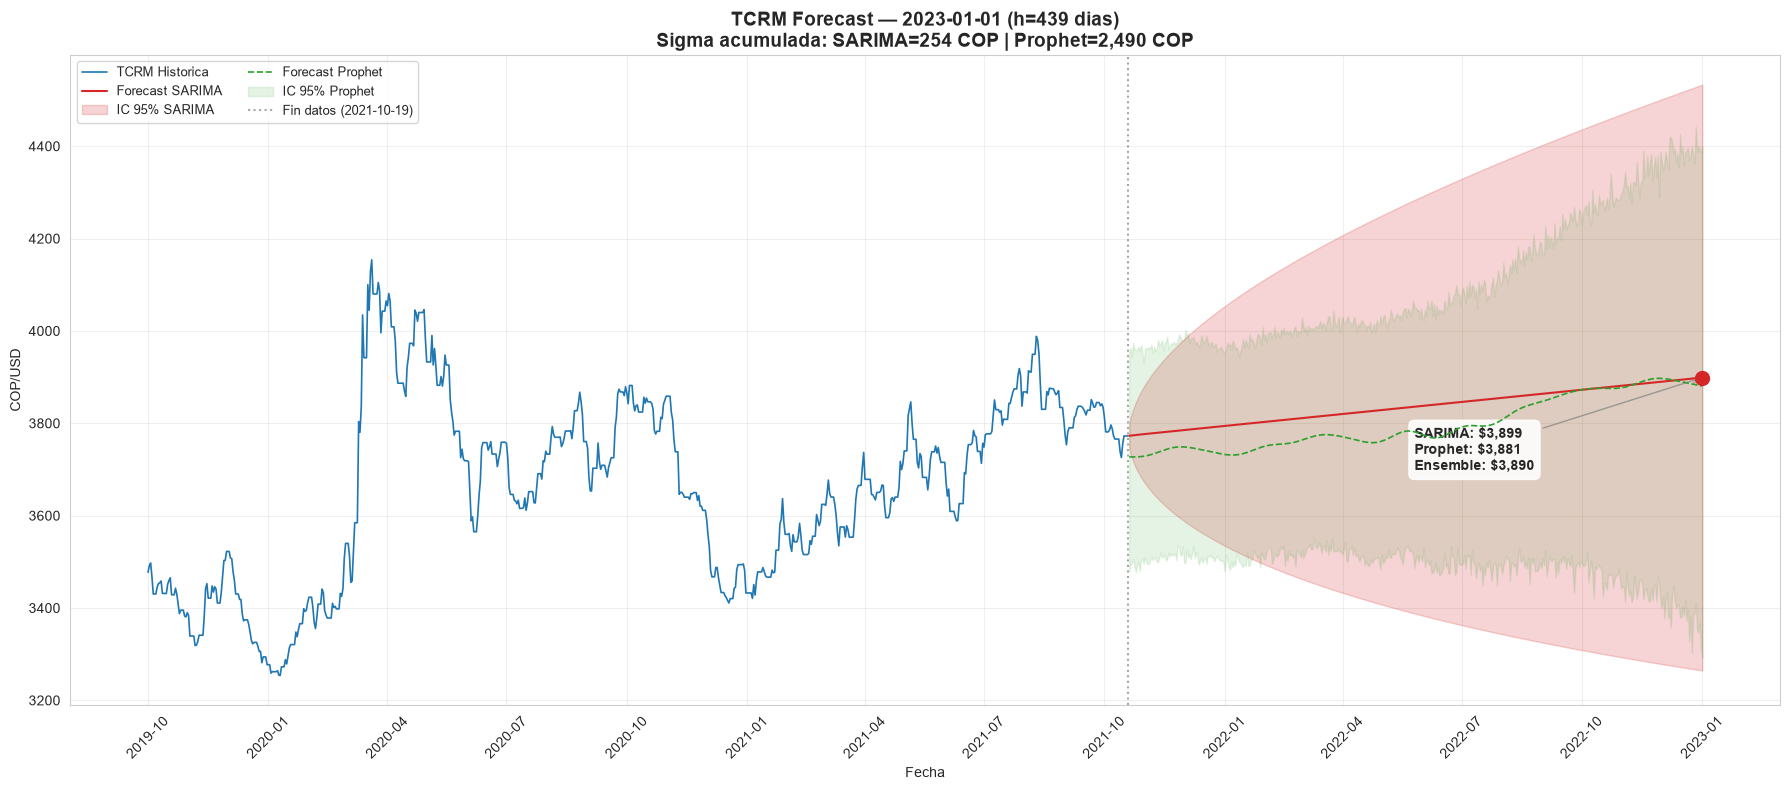

In [14]:
fig, ax = plt.subplots(figsize=(18, 8))

# Historico desde 2019-10
mask = tcrm_series.index >= pd.Timestamp("2019-10-01")
ax.plot(tcrm_series.index[mask], tcrm_series.values[mask],
        linewidth=1.2, color="#1f77b4", label="TCRM Historica", zorder=3)

# Forecast SARIMA
ax.plot(fc_dates, sarima_fc_series.values,
        linewidth=1.5, color="#d62728", label="Forecast SARIMA", zorder=4)
ax.fill_between(fc_dates, sarima_ci[:, 0], sarima_ci[:, 1],
                alpha=0.2, color="#d62728", label="IC 95% SARIMA")

# Forecast Prophet
ax.plot(prophet_fc_future["ds"], prophet_fc_future["yhat"],
        linewidth=1.2, color="#2ca02c", linestyle="--", label="Forecast Prophet", zorder=4)
ax.fill_between(prophet_fc_future["ds"],
                prophet_fc_future["yhat_lower"], prophet_fc_future["yhat_upper"],
                alpha=0.12, color="#2ca02c", label="IC 95% Prophet")

# Linea fin de dataset
ax.axvline(pd.Timestamp("2021-10-19"), color="gray", linestyle=":",
           linewidth=1.5, alpha=0.7, label="Fin datos (2021-10-19)")

# Punto 2023-01-01
ax.scatter([FORECAST_END], [sarima_pred_2023], color="#d62728", s=100, zorder=10)
ax.annotate(
    f"SARIMA: ${sarima_pred_2023:,.0f}\nProphet: ${prophet_pred_2023:,.0f}\nEnsemble: ${ensemble:,.0f}",
    xy=(FORECAST_END, sarima_pred_2023),
    xytext=(FORECAST_END - pd.DateOffset(days=220), sarima_pred_2023 - 200),
    fontsize=10, fontweight="bold",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.9),
    arrowprops=dict(arrowstyle="->", color="gray", alpha=0.7),
)

ax.set_title(f"TCRM Forecast — 2023-01-01 (h={HORIZON} dias)\n"
             f"Sigma acumulada: SARIMA={sarima_sigma_h:,.0f} COP | Prophet={prophet_sigma_h:,.0f} COP",
             fontsize=14, fontweight="bold")
ax.set_xlabel("Fecha"); ax.set_ylabel("COP/USD")
ax.legend(loc="upper left", fontsize=9, ncol=2)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
plt.xticks(rotation=45)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

---
## PASO 7 — Resumen final del Punto 2

| Sub-punto | Resultado |
|-----------|----------|
| **2.a** — TCRM cedula (2010-04-19) | **$1,942.21 COP** — coincide exactamente con el valor de referencia |
| **2.b** — Integridad de la serie | 10,915 dias totales, 7,188 originales, 3,727 imputados (forward-fill SFC) |
| **2.c** — Analisis exploratorio | 6 regimenes cambiarios identificados, clusters de volatilidad en crisis |
| **2.d** — Forecast 2023-01-01 | SARIMA + Prophet; sigma_h acumulada estimada para h=439 dias |

**Notas metodologicas:**
- Imputacion segun Circular DODM-146 de la Superintendencia Financiera de Colombia.
- La desviacion estandar acumulada asume independencia de errores (aproximacion razonable para horizontes moderados).
- Para capturar heterocedasticidad, una extension natural seria incorporar un modelo GARCH sobre los residuos.